# E242 — Health-based plasticity control on the Phase 1.2.5 correlated stream

**complete** · Full oracle analysis complete · predictive controller gate missed

Updated 2026-11-23T22:35:52+01:00 Stockholm time · Current stage ETA **—**

**200/200** source states in the current stage.

The archived BDD100K walk supplies the 18-regime order and keyframe positions. Exact native video captures supply the 64 consecutive frames at registered source slots. The first 16 have arrived before branching. The +1 and +16 actions and the optional 32-step continuation stay inside that capture. Capture-level partitioning creates 24 development, 40 test, and 24 prospective sources per seed. The five TinyMAE seeds use the archived within-regime orders in rotation. Remaining keyframes retain their relative phase order inside each disjoint partition.

The 64 px MAE, AdamW, masks, and base learning rate match the prior Phase 1.2 +16 MAE work. A batch of four makes 25% and 50% replay exact. Each incoming batch uses already-observed frames for its other slots. Historical replay substitutes slots using a past-only 128-image reservoir. The reference trains at 1× through its first 8,000 arrivals and at 0.25× afterward. All branches restore the same model, optimizer, RNG and observation state. Receipt IDs identify those states. Each source uses two paired mask draws.

Health uses separate, fixed 256-capture new and historical banks, with a chronological nearest-regime fallback when needed. Bank captures are disjoint across source splits and permanently excluded from learning and the independent annotated probes. Bank retrieval excludes same-capture matches and visually near-identical thumbnails. Historical CKA is measured against each seed's frozen initialization. The CKA penalty uses weight 0.075 and scale 0.05 when observed historical loss or retrieval also worsens.

The downstream score is 60% new plus 40% historical macro balanced accuracy, with four equally weighted primary tasks (scene, weather, traffic light, pedestrian). Lighting is logged separately. Each probe is refitted on fixed captures. New and old task queries are disjoint and include 32 images per class. Confidence intervals resample model seeds and source captures independently, keep paired draws within each cell, and condition on the common external labeled corpus.

Stage C opens only for a horizon where both the heuristic and downstream oracle beat the development-selected fixed rule by at least +0.25 pp with a positive interval, in both realized-draw and independent-mask comparisons. The prospective ridge trains on development health changes. Its inputs are observed before the first incoming frame and its chosen action is executed once in a separate chronological stream.


## Development-locked calibration

| Horizon | Best fixed action | RMS scales (new loss, new margin, old loss, old margin) |
| --- | --- | --- |
| +1 | A1 incoming 0.125× | 0.0024178, 0.000448942, 0.0025719, 0.000405794 |
| +16 | A0 skip | 0.0353407, 0.00457063, 0.0378163, 0.00425037 |

## Held-out oracle decision

| Horizon | Downstream headroom (pp) | Independent-draw headroom (pp) | Heuristic value (pp) | Independent-draw heuristic (pp) | Gate |
| --- | --- | --- | --- | --- | --- |
| +1 | +0.217 [+0.170, +0.284] | +0.151 [+0.103, +0.215] | +0.001 [-0.039, +0.052] | +0.002 [-0.036, +0.052] | missed |
| +16 | +0.773 [+0.611, +0.970] | +0.530 [+0.357, +0.730] | -0.111 [-0.348, +0.112] | -0.116 [-0.366, +0.129] | missed |

### Paired +16 minus +1 comparison

| Quantity | Difference [95% interval] |
| --- | --- |
| value | -0.112 [-0.360, +0.127] |
| spearman | +0.010 [-0.209, +0.210] |
| regret | +0.667 [+0.435, +0.923] |

## +1 · reward ablations against A1 incoming 0.125×

| Objective | Value (pp) | Independent draw (pp) | Spearman | Kendall | Top-action agreement | Regret (pp) | Mean optimizer steps |
| --- | --- | --- | --- | --- | --- | --- | --- |
| loss only | -0.012 [-0.053, +0.024] | -0.014 [-0.057, +0.022] | -0.062 [-0.203, +0.083] | -0.050 [-0.173, +0.074] | +0.345 [+0.230, +0.472] | +0.230 [+0.164, +0.314] | 0.17 |
| retrieval only | +0.007 [-0.033, +0.067] | +0.007 [-0.030, +0.061] | -0.014 [-0.137, +0.102] | -0.012 [-0.117, +0.089] | +0.325 [+0.237, +0.417] | +0.210 [+0.165, +0.253] | 0.35 |
| combined | +0.001 [-0.040, +0.052] | +0.002 [-0.036, +0.052] | -0.040 [-0.182, +0.093] | -0.030 [-0.154, +0.089] | +0.338 [+0.237, +0.448] | +0.217 [+0.163, +0.271] | 0.23 |
| spectral + CKA | +0.001 [-0.040, +0.052] | +0.002 [-0.036, +0.052] | -0.040 [-0.182, +0.093] | -0.030 [-0.154, +0.089] | +0.338 [+0.237, +0.448] | +0.217 [+0.163, +0.271] | 0.23 |
| full reward | +0.001 [-0.039, +0.052] | +0.002 [-0.036, +0.052] | -0.041 [-0.182, +0.092] | -0.031 [-0.154, +0.087] | +0.340 [+0.240, +0.450] | +0.216 [+0.163, +0.270] | 0.23 |

| Action | Times selected | Mean optimizer steps | Mean action + evaluation seconds |
| --- | --- | --- | --- |
| A0 skip | 310 | 0.00 | 0.219 |
| A1 incoming 0.125× | 0 | 1.00 | 0.232 |
| A2 incoming 0.5× | 3 | 1.00 | 0.232 |
| A3 incoming 1× | 53 | 1.00 | 0.232 |
| A4 25% replay | 5 | 1.00 | 0.232 |
| A5 50% replay | 29 | 1.00 | 0.232 |

| Representative clip | Seed | Regime | Advantage over fixed (pp) | Actions by draw |
| --- | --- | --- | --- | --- |
| 03f65112-049cca26 | 2026 | 9 | -1.042 | A3 incoming 1×, A3 incoming 1× |
| 01a4deab-0f7d41cc | 2028 | 8 | -0.677 | A3 incoming 1×, A3 incoming 1× |
| 22d49063-3c1935ca | 2028 | 12 | -0.547 | A0 skip, A0 skip |
| aa16d322-f9c853f0 | 2026 | 15 | +0.977 | A5 50% replay, A5 50% replay |
| 1632f033-b79d42b9 | 2026 | 10 | +0.872 | A2 incoming 0.5×, A5 50% replay |
| aa16d322-f9c853f0 | 2028 | 15 | +0.469 | A0 skip, A0 skip |

After the fixed 32-step continuation on 20 paired draws, quality changed +0.086 pp after the heuristic action and +0.055 pp after the fixed action.

## +16 · reward ablations against A0 skip

| Objective | Value (pp) | Independent draw (pp) | Spearman | Kendall | Top-action agreement | Regret (pp) | Mean optimizer steps |
| --- | --- | --- | --- | --- | --- | --- | --- |
| loss only | -0.083 [-0.321, +0.142] | -0.098 [-0.334, +0.124] | -0.020 [-0.151, +0.103] | -0.012 [-0.117, +0.087] | +0.165 [+0.098, +0.237] | +0.856 [+0.665, +1.068] | 6.84 |
| retrieval only | -0.129 [-0.370, +0.099] | -0.117 [-0.352, +0.114] | -0.040 [-0.189, +0.109] | -0.027 [-0.143, +0.091] | +0.150 [+0.085, +0.225] | +0.902 [+0.698, +1.134] | 9.56 |
| combined | -0.108 [-0.347, +0.120] | -0.108 [-0.359, +0.138] | -0.028 [-0.184, +0.120] | -0.014 [-0.136, +0.103] | +0.160 [+0.092, +0.237] | +0.881 [+0.668, +1.121] | 8.92 |
| spectral + CKA | -0.110 [-0.349, +0.114] | -0.114 [-0.365, +0.132] | -0.028 [-0.184, +0.119] | -0.014 [-0.137, +0.102] | +0.160 [+0.092, +0.237] | +0.883 [+0.670, +1.123] | 8.88 |
| full reward | -0.111 [-0.348, +0.112] | -0.116 [-0.366, +0.129] | -0.031 [-0.186, +0.115] | -0.016 [-0.139, +0.100] | +0.160 [+0.087, +0.242] | +0.884 [+0.666, +1.124] | 8.44 |

| Action | Times selected | Mean optimizer steps | Mean action + evaluation seconds |
| --- | --- | --- | --- |
| A0 skip | 189 | 0.00 | 0.218 |
| A1 incoming 0.125× | 7 | 16.00 | 0.422 |
| A2 incoming 0.5× | 2 | 16.00 | 0.422 |
| A3 incoming 1× | 1 | 16.00 | 0.422 |
| A4 25% replay | 6 | 16.00 | 0.422 |
| A5 50% replay | 131 | 16.00 | 0.422 |
| A6 8 incoming then 8 replay | 24 | 16.00 | 0.422 |
| A7 interleaved blocks of four | 40 | 16.00 | 0.422 |

| Representative clip | Seed | Regime | Advantage over fixed (pp) | Actions by draw |
| --- | --- | --- | --- | --- |
| 44ef3a83-4c9452e6 | 2028 | 12 | -3.802 | A5 50% replay, A5 50% replay |
| 44ef3a83-4c9452e6 | 2027 | 12 | -3.307 | A7 interleaved blocks of four, A5 50% replay |
| 534fff4c-0880089d | 2029 | 4 | -2.656 | A5 50% replay, A6 8 incoming then 8 replay |
| aa16d322-f9c853f0 | 2030 | 15 | +2.891 | A5 50% replay, A5 50% replay |
| 48be98fb-7bbe24d8 | 2030 | 0 | +2.188 | A2 incoming 0.5×, A4 25% replay |
| 70db4cac-a8e88321 | 2029 | 1 | +2.044 | A5 50% replay, A5 50% replay |

After the fixed 32-step continuation on 20 paired draws, quality changed +0.086 pp after the heuristic action and +0.047 pp after the fixed action.

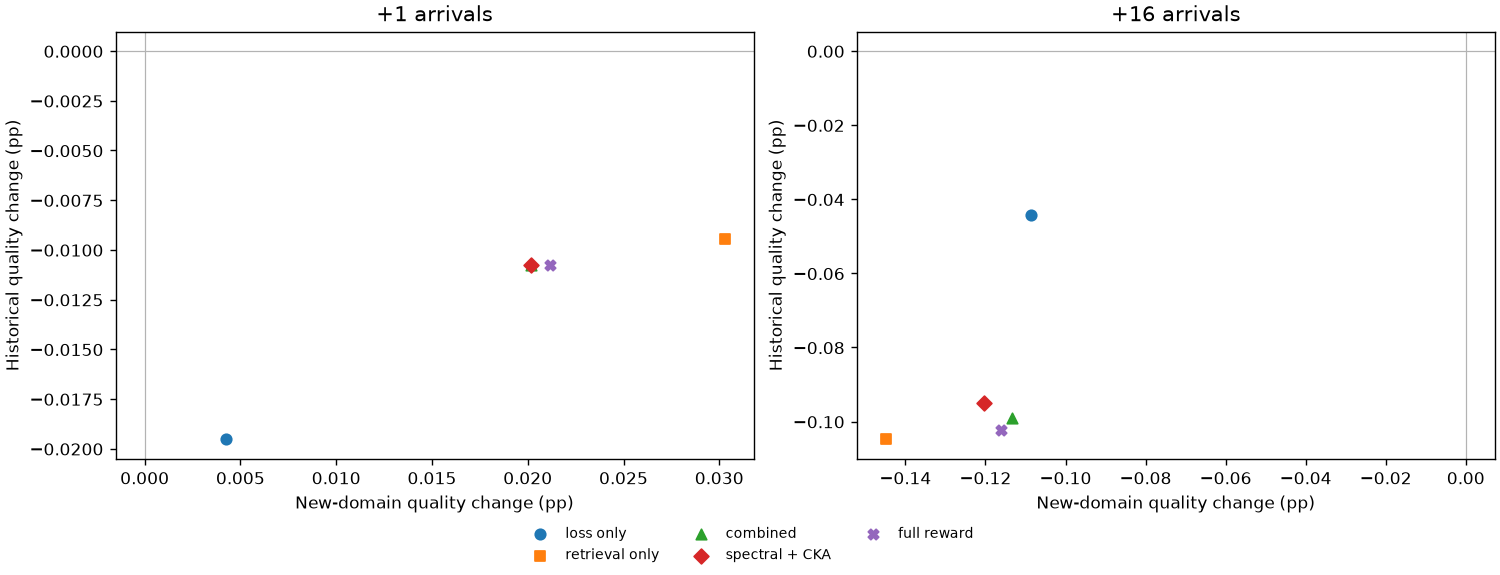

**Decision:** The held-out oracle gate stayed closed. The experiment provides no basis for fitting an MPC predictor to these health rewards and actions.